In [1]:
from plot.Plot import StockPlot
from tickers import DOW_30_TICKER
from fetcher import YahooDataFetcher
from backtest.Strategy import Backtester
from indicators.Momentum import MomentumIndicators
from preprocess.PreProcessing import DataPreProcessing

In [2]:
interval = '1d'  # Can change to '1d', '1wk', '1mo', etc.
end_date = None  # If None, it will download up to the latest available data
start_date = None  # If None, it will download max available data or adjust based on the interval
# tickers = ['600519.SS', '601318.SS', '000002.SZ', '0700.HK']
# Create an instance of the StockDataDownloader
downloader = YahooDataFetcher(country='usa', tickers=["SPX"], start=start_date, end=end_date, interval=interval)

Deleted: ./data/usa/SPX_2019-12-12_2024-12-10_1d.csv
Deleted: ./data/usa/combined_output.csv
All files have been deleted.


In [3]:
# Download the stock data
downloader.download_data()

data = downloader.get_data()

# print(data.head(10))

[*********************100%***********************]  1 of 1 completed

1 Failed download:
['SPX']: YFPricesMissingError('$%ticker%: possibly delisted; no price data found  (1d 2019-12-13 17:58:05.049671 -> 2024-12-11 17:58:05.049671)')


No data available for SPX. Trying with ^SPX...


[*********************100%***********************]  1 of 1 completed

Data successfully saved to ./data/usa/SPX_2019-12-13_2024-12-11_1d.csv
All tickers Download complete.
All CSV files have been combined into ./data/usa/combined_output.csv



/Users/habib/Desktop/Projects/FinDRL/fetcher/YahooDataFetcher.py:143: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [4]:
data

,Datetime,index,Open,High,Low,Close,Adj Close,Volume,Ticker
0,2019-12-13 00:00:00+00:00,0,3166.649902,3182.679932,3156.510010,3168.800049,3168.800049,3757650000,SPX
1,2019-12-16 00:00:00+00:00,1,3183.629883,3197.709961,3183.629883,3191.449951,3191.449951,4070200000,SPX
2,2019-12-17 00:00:00+00:00,2,3195.399902,3198.219971,3191.030029,3192.520020,3192.520020,3842940000,SPX
3,2019-12-18 00:00:00+00:00,3,3195.209961,3198.479980,3191.139893,3191.139893,3191.139893,4029950000,SPX
4,2019-12-19 00:00:00+00:00,4,3192.320068,3205.479980,3192.320068,3205.370117,3205.370117,3784360000,SPX
...,...,...,...,...,...,...,...,...,...
1252,2024-12-05 00:00:00+00:00,1252,6089.029785,6094.549805,6072.899902,6075.109863,6075.109863,4212020000,SPX
1253,2024-12-06 00:00:00+00:00,1253,6081.379883,6099.970215,6079.979980,6090.270020,6090.270020,3924830000,SPX
1254,2024-12-09 00:00:00+00:00,1254,6083.009766,6088.509766,6048.629883,6052.850098,6052.850098,4556460000,SPX
1255,2024-12-10 00:00:00+00:00,1255,6057.589844,6065.399902,6029.890137,6034.910156,6034.910156,4048410000,SPX


In [5]:
# df = downloader.processing(data)
df = DataPreProcessing(data)

In [6]:
ndf = df.processed(columns=["index"])

Successfully set 'datetime' as the datetime index.
Dropped columns: ['index']


In [7]:
ndf

,open,high,low,close,adj close,volume,ticker
datetime,,,,,,,
2019-12-13 00:00:00+00:00,3166.649902,3182.679932,3156.510010,3168.800049,3168.800049,3757650000,SPX
2019-12-16 00:00:00+00:00,3183.629883,3197.709961,3183.629883,3191.449951,3191.449951,4070200000,SPX
2019-12-17 00:00:00+00:00,3195.399902,3198.219971,3191.030029,3192.520020,3192.520020,3842940000,SPX
2019-12-18 00:00:00+00:00,3195.209961,3198.479980,3191.139893,3191.139893,3191.139893,4029950000,SPX
2019-12-19 00:00:00+00:00,3192.320068,3205.479980,3192.320068,3205.370117,3205.370117,3784360000,SPX
...,...,...,...,...,...,...,...
2024-12-05 00:00:00+00:00,6089.029785,6094.549805,6072.899902,6075.109863,6075.109863,4212020000,SPX
2024-12-06 00:00:00+00:00,6081.379883,6099.970215,6079.979980,6090.270020,6090.270020,3924830000,SPX
2024-12-09 00:00:00+00:00,6083.009766,6088.509766,6048.629883,6052.850098,6052.850098,4556460000,SPX


In [8]:
mind = MomentumIndicators(ndf)

In [9]:
ndata = mind.calculate()

In [10]:
ndata

,open,high,low,close,adj close,volume,ticker,ao_fast_10_slow_20,ao_fast_10_slow_25,ao_fast_10_slow_30,...,uo_fast_14_slow_35,uo_fast_16_slow_20,uo_fast_16_slow_25,uo_fast_16_slow_30,uo_fast_16_slow_35,uo_fast_18_slow_20,uo_fast_18_slow_25,uo_fast_18_slow_30,uo_fast_18_slow_35,willr_
datetime,,,,,,,,,,,,,,,,,,,,,
2019-12-13 00:00:00+00:00,3166.649902,3182.679932,3156.510010,3168.800049,3168.800049,3757650000,SPX,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-16 00:00:00+00:00,3183.629883,3197.709961,3183.629883,3191.449951,3191.449951,4070200000,SPX,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-17 00:00:00+00:00,3195.399902,3198.219971,3191.030029,3192.520020,3192.520020,3842940000,SPX,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-18 00:00:00+00:00,3195.209961,3198.479980,3191.139893,3191.139893,3191.139893,4029950000,SPX,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-12-19 00:00:00+00:00,3192.320068,3205.479980,3192.320068,3205.370117,3205.370117,3784360000,SPX,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-05 00:00:00+00:00,6089.029785,6094.549805,6072.899902,6075.109863,6075.109863,4212020000,SPX,35.228503,76.974692,96.061336,...,64.054013,63.405519,63.275121,62.851454,62.706447,63.048820,62.918423,62.494756,62.349749,-8.048331
2024-12-06 00:00:00+00:00,6081.379883,6099.970215,6079.979980,6090.270020,6090.270020,3924830000,SPX,45.474524,79.408213,102.909359,...,70.772933,67.845951,68.601859,67.417251,67.488605,67.379710,68.135618,66.951010,67.022364,-3.964439
2024-12-09 00:00:00+00:00,6083.009766,6088.509766,6048.629883,6052.850098,6052.850098,4556460000,SPX,52.770276,77.574219,105.997689,...,67.155005,65.390037,66.429511,65.349422,65.148870,64.264638,65.304112,64.224022,64.023471,-19.257840


In [11]:
ndata.columns

Index(['open', 'high', 'low', 'close', 'adj close', 'volume', 'ticker',
       'ao_fast_10_slow_20', 'ao_fast_10_slow_25', 'ao_fast_10_slow_30',
       ...
       'uo_fast_14_slow_35', 'uo_fast_16_slow_20', 'uo_fast_16_slow_25',
       'uo_fast_16_slow_30', 'uo_fast_16_slow_35', 'uo_fast_18_slow_20',
       'uo_fast_18_slow_25', 'uo_fast_18_slow_30', 'uo_fast_18_slow_35',
       'willr_'],
      dtype='object', length=1751)

In [12]:
duplicates = ndata.index[ndata.index.duplicated()]
duplicates

DatetimeIndex([], dtype='datetime64[ns, UTC]', name='datetime', freq=None)

In [14]:
backtester = Backtester(ndata[50:])
backtester.prepare_data()

# Backtest all indicators with thresholds
results, updated_data = backtester.backtest_all_indicators(low_range=0, high_range=100, step=10)

Backtesting indicator: ao_fast_10_slow_20
Backtesting indicator: ao_fast_10_slow_25
Backtesting indicator: ao_fast_10_slow_30
Backtesting indicator: ao_fast_10_slow_35
Backtesting indicator: ao_fast_12_slow_20
Backtesting indicator: ao_fast_12_slow_25
Backtesting indicator: ao_fast_12_slow_30
Backtesting indicator: ao_fast_12_slow_35
Backtesting indicator: ao_fast_14_slow_20
Backtesting indicator: ao_fast_14_slow_25
Backtesting indicator: ao_fast_14_slow_30
Backtesting indicator: ao_fast_14_slow_35
Backtesting indicator: ao_fast_16_slow_20
Backtesting indicator: ao_fast_16_slow_25
Backtesting indicator: ao_fast_16_slow_30
Backtesting indicator: ao_fast_16_slow_35
Backtesting indicator: ao_fast_18_slow_20
Backtesting indicator: ao_fast_18_slow_25
Backtesting indicator: ao_fast_18_slow_30
Backtesting indicator: ao_fast_18_slow_35
Backtesting indicator: apo_fast_10_slow_20
Backtesting indicator: apo_fast_10_slow_25
Backtesting indicator: apo_fast_10_slow_30
Backtesting indicator: apo_fast

In [15]:
# results.head(1)

In [16]:
updated_data["ao_fast_10_slow_20"]

,datetime,ao_fast_10_slow_20,return,label,signal,entry_time,exit_time,profit
datetime,,,,,,,,
2020-02-26 00:00:00+00:00,2020-02-26 00:00:00+00:00,5.485010,-0.007488,0,1,2020-02-26 00:00:00+00:00,2020-02-27 00:00:00+00:00,-0.007488
2020-02-27 00:00:00+00:00,2020-02-27 00:00:00+00:00,-16.078992,-0.027356,0,1,2020-02-27 00:00:00+00:00,2020-02-28 00:00:00+00:00,-0.027356
2020-02-28 00:00:00+00:00,2020-02-28 00:00:00+00:00,-44.752747,0.012794,1,1,2020-02-28 00:00:00+00:00,2020-03-02 00:00:00+00:00,0.012794
2020-03-02 00:00:00+00:00,2020-03-02 00:00:00+00:00,-68.765741,0.038984,1,1,2020-03-02 00:00:00+00:00,2020-03-03 00:00:00+00:00,0.038984
2020-03-03 00:00:00+00:00,2020-03-03 00:00:00+00:00,-89.860504,-0.030063,0,1,2020-03-03 00:00:00+00:00,2020-03-04 00:00:00+00:00,-0.030063
...,...,...,...,...,...,...,...,...
2024-12-04 00:00:00+00:00,2024-12-04 00:00:00+00:00,25.078003,0.002817,1,1,2024-12-04 00:00:00+00:00,2024-12-05 00:00:00+00:00,0.002817
2024-12-05 00:00:00+00:00,2024-12-05 00:00:00+00:00,35.228503,-0.002286,0,1,2024-12-05 00:00:00+00:00,2024-12-06 00:00:00+00:00,-0.002286
2024-12-06 00:00:00+00:00,2024-12-06 00:00:00+00:00,45.474524,0.001462,1,1,2024-12-06 00:00:00+00:00,2024-12-09 00:00:00+00:00,0.001462


In [17]:
updated_data["ao_fast_10_slow_20"].columns

Index(['datetime', 'ao_fast_10_slow_20', 'return', 'label', 'signal',
       'entry_time', 'exit_time', 'profit'],
      dtype='object')

In [27]:
updated_data["ao_fast_10_slow_20"]

,datetime,ao_fast_10_slow_20,return,label,signal,entry_time,exit_time,profit
datetime,,,,,,,,
2020-02-26 00:00:00+00:00,2020-02-26 00:00:00+00:00,5.485010,-0.007488,0,1,2020-02-26 00:00:00+00:00,2020-02-27 00:00:00+00:00,-0.007488
2020-02-27 00:00:00+00:00,2020-02-27 00:00:00+00:00,-16.078992,-0.027356,0,1,2020-02-27 00:00:00+00:00,2020-02-28 00:00:00+00:00,-0.027356
2020-02-28 00:00:00+00:00,2020-02-28 00:00:00+00:00,-44.752747,0.012794,1,1,2020-02-28 00:00:00+00:00,2020-03-02 00:00:00+00:00,0.012794
2020-03-02 00:00:00+00:00,2020-03-02 00:00:00+00:00,-68.765741,0.038984,1,1,2020-03-02 00:00:00+00:00,2020-03-03 00:00:00+00:00,0.038984
2020-03-03 00:00:00+00:00,2020-03-03 00:00:00+00:00,-89.860504,-0.030063,0,1,2020-03-03 00:00:00+00:00,2020-03-04 00:00:00+00:00,-0.030063
...,...,...,...,...,...,...,...,...
2024-12-04 00:00:00+00:00,2024-12-04 00:00:00+00:00,25.078003,0.002817,1,1,2024-12-04 00:00:00+00:00,2024-12-05 00:00:00+00:00,0.002817
2024-12-05 00:00:00+00:00,2024-12-05 00:00:00+00:00,35.228503,-0.002286,0,1,2024-12-05 00:00:00+00:00,2024-12-06 00:00:00+00:00,-0.002286
2024-12-06 00:00:00+00:00,2024-12-06 00:00:00+00:00,45.474524,0.001462,1,1,2024-12-06 00:00:00+00:00,2024-12-09 00:00:00+00:00,0.001462


In [42]:
# # Plotting
# plotter = Plotting(data=ndata, bt_result=results, indicator_df=updated_data, indicator_name="ao_fast_10_slow_20")
# plotter.plot()

BT Result
            indicator  low_threshold  high_threshold  total_profit  accuracy  \
0  ao_fast_10_slow_20              0              10     -0.174626  0.193041   
1  ao_fast_10_slow_20              0              20     -0.023468  0.228666   

   sharpe_ratio  cumulative_return  
0     -0.014642          -0.174626  
1     -0.002031          -0.023468  
Ind str data
                                           datetime  ao_fast_10_slow_20  \
datetime                                                                  
2020-02-26 00:00:00+00:00 2020-02-26 00:00:00+00:00            5.485010   
2020-02-27 00:00:00+00:00 2020-02-27 00:00:00+00:00          -16.078992   

                             return  label  signal                entry_time  \
datetime                                                                       
2020-02-26 00:00:00+00:00 -0.007488      0       1 2020-02-26 00:00:00+00:00   
2020-02-27 00:00:00+00:00 -0.027356      0       1 2020-02-27 00:00:00+00:00   

   

KeyError: 'entry_time'

In [41]:
results

,indicator,low_threshold,high_threshold,total_profit,accuracy,sharpe_ratio,cumulative_return
0,ao_fast_10_slow_20,0,10,-0.174626,0.193041,-0.014642,-0.174626
1,ao_fast_10_slow_20,0,20,-0.023468,0.228666,-0.002031,-0.023468
2,ao_fast_10_slow_20,0,30,-0.078975,0.273405,-0.007071,-0.078975
3,ao_fast_10_slow_20,0,40,-0.028498,0.318144,-0.002633,-0.028498
4,ao_fast_10_slow_20,0,50,0.002816,0.362883,0.000269,0.002816
...,...,...,...,...,...,...,...
78565,label,60,80,0.301263,0.538525,0.024901,0.301263
78566,label,60,90,0.301263,0.538525,0.024901,0.301263
78567,label,70,80,0.301263,0.538525,0.024901,0.301263
78568,label,70,90,0.301263,0.538525,0.024901,0.301263


In [103]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt

class Plotting:
    def __init__(self, data=None, bt_result=None, indicator_df=None, indicator_name=None):
        """
        Initialize the Plotting class.
        :param data: Main DataFrame containing the time series data.
        :param bt_result: Optional DataFrame containing backtesting results.
        :param indicator_df: DataFrame or dict with indicators and trade signals.
        :param indicator_name: Name of the indicator to highlight on the plot.
        """
        self.data = data.copy()
        self.bt_result = bt_result.copy()
        self.indicator_name = indicator_name
        self.indicator_df =  pd.DataFrame(indicator_df[indicator_name]) if isinstance(indicator_df, dict) else indicator_df[indicator_name].copy()
        
    def plot(self, num_days=15, zoom_margin=0, **plot_kwargs):
        """
        Plot the data, backtesting results, and indicator signals using mplfinance.
        
        :param zoom_margin: Number of rows to zoom into around the trades.
        :param plot_kwargs: Additional plotting arguments.
        """
        # # Ensure the datetime column exists
        # Ensure the index is a datetime object
        if not isinstance(self.data.index, pd.DatetimeIndex):
            raise KeyError("The dataset index must be a DatetimeIndex. Please ensure the datetime column is set as the index.")
    
        # Subset the data if num_days is provided
        if num_days is not None:
            end_date = self.data.index.max()
            start_date = end_date - pd.Timedelta(days=num_days)
            data_to_plot = self.data.loc[start_date:end_date]
        else:
            data_to_plot = self.data
    
        # Convert data for mplfinance
        mpf_data = data_to_plot[['open', 'high', 'low', 'close', 'volume']]
    
        # Initialize additional plots
        add_plots = []
    
        # Plot signals if indicator data is provided
        if self.indicator_df is not None:
            if 'entry_time' in self.indicator_df.columns and 'exit_time' in self.indicator_df.columns:
                # Subset indicator data to match the plotting range
                start_time = data_to_plot.index.min()
                end_time = data_to_plot.index.max()
    
                entry_times = pd.to_datetime(self.indicator_df['entry_time']).dropna()
                exit_times = pd.to_datetime(self.indicator_df['exit_time']).dropna()
    
                entry_times = entry_times[(entry_times >= start_time) & (entry_times <= end_time)]
                exit_times = exit_times[(exit_times >= start_time) & (exit_times <= end_time)]
    
                # Align with the plotting range
                entry_prices = self.data.loc[entry_times, 'close']
                exit_prices = self.data.loc[exit_times, 'close']
    
                # Scatter plot entries and exits
                add_plots.append(
                    mpf.make_addplot(entry_prices, scatter=True, markersize=50, marker='^', color='green')
                )
                add_plots.append(
                    mpf.make_addplot(exit_prices, scatter=True, markersize=50, marker='v', color='red')
                )
    
        # Plot the data with mplfinance
        mpf.plot(
            mpf_data,
            type='candle',
            addplot=add_plots,
            volume=True,
            style='yahoo',
            title=f"Trading Chart ({num_days} Days)" if num_days else "Trading Chart",
            **plot_kwargs
        )

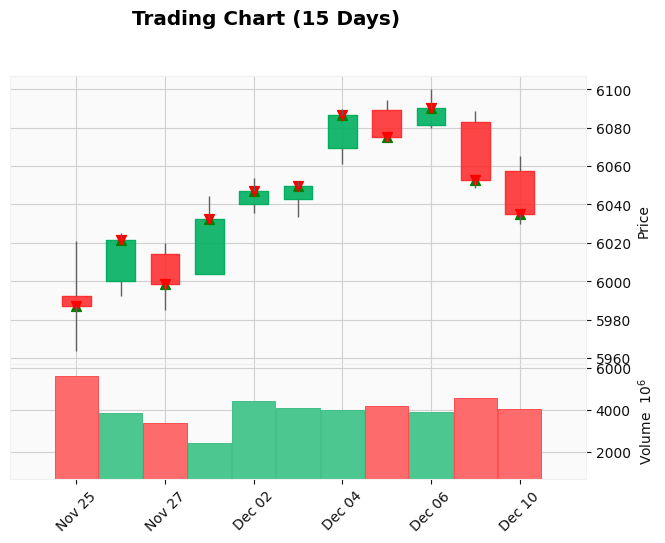

In [104]:
# Example usage
plotter = Plotting(data=ndata, bt_result=results, indicator_df=updated_data, indicator_name="ao_fast_10_slow_20")
plotter.plot()

In [98]:
ndata.columns

Index(['open', 'high', 'low', 'close', 'adj close', 'volume', 'ticker',
       'ao_fast_10_slow_20', 'ao_fast_10_slow_25', 'ao_fast_10_slow_30',
       ...
       'uo_fast_14_slow_35', 'uo_fast_16_slow_20', 'uo_fast_16_slow_25',
       'uo_fast_16_slow_30', 'uo_fast_16_slow_35', 'uo_fast_18_slow_20',
       'uo_fast_18_slow_25', 'uo_fast_18_slow_30', 'uo_fast_18_slow_35',
       'willr_'],
      dtype='object', length=1751)

In [105]:
import pandas_ta as ta

In [106]:
mom_indicators = ta.Category["momentum"]

In [107]:
mom_indicators

['ao',
 'apo',
 'bias',
 'bop',
 'brar',
 'cci',
 'cfo',
 'cg',
 'cmo',
 'coppock',
 'cti',
 'er',
 'eri',
 'fisher',
 'inertia',
 'kdj',
 'kst',
 'macd',
 'mom',
 'pgo',
 'ppo',
 'psl',
 'pvo',
 'qqe',
 'roc',
 'rsi',
 'rsx',
 'rvgi',
 'slope',
 'smi',
 'squeeze',
 'squeeze_pro',
 'stc',
 'stoch',
 'stochrsi',
 'td_seq',
 'trix',
 'tsi',
 'uo',
 'willr']